# Fase 9 — Evaluación final del modelo congelado sobre prueba v3

Se revisaron informe, plan y especificación de fase 8, modelo joblib, manifiesto v3 y decision_policy.py. Se evalúa una vez logística congelada: sin fit, recalibración, cambios de capacidad/empates o selección de modelos. No se preparan entregables de fase 10. La evaluación sigue siendo retrospectiva y exploratoria por exposición previa.

## 1. Orden obligatorio y política

Preflight sin etiquetas: SHA de modelo/especificación/entradas, entorno, hiperparámetros, 14 entradas y 192 transformadas, IDs de prueba sin solapamiento. Se bloquean métodos fit/fit_transform durante inferencia y se compara huella de parámetros aprendidos. Se realiza una llamada predict_proba, se prioriza sin y, se guardan scores/decisiones y SHA; solo después se leen etiquetas.

Política ya fijada: top floor(0,20*n_mes) por mes de llegada, ambos hoteles juntos. Score descendente, empates exactos por SHA256 de 42|ID y después ID numérico, sin redondeo de score. Es ranking por capacidad, no un umbral fijo. No se reentrena con validación. Un recibo persistente bloquea nuevas inferencias en reejecución.

In [1]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Verificar y reproducir la evaluación congelada; un recibo completo evita repetir inferencia.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
from pathlib import Path
import sys,json
from IPython.display import display,Image
ROOT=Path.cwd()
if not (ROOT/"src").is_dir(): ROOT=ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.final_evaluation import run_evaluation
tables,result,receipt=run_evaluation(ROOT)
print("Llamadas de inferencia registradas:",receipt["llamadas_predict_proba"])
print("Reentrenamientos:",receipt["reentrenamientos"])
print("Congelación scores:",receipt["timestamp_congelacion_utc"])
print("Primer acceso etiquetas:",receipt["timestamp_primer_acceso_etiquetas_utc"])
from src.evaluation_narrative import add_narrative
add_narrative(ROOT)

Reproducción de resultados congelados: cero llamadas de inferencia, sin entrenamiento.


Llamadas de inferencia registradas: 1
Reentrenamientos: 0
Congelación scores: 2026-10-18T16:06:25.070126+00:00
Primer acceso etiquetas: 2026-10-18T16:06:25.256968+00:00


## 2. Resultado final y comparación con validación

Precision/recall/F1 y matriz evalúan prioridad de seguimiento. ROC-AUC/AP usan scores continuos; Brier y medias evalúan error probabilístico. No se sustituye la política por 0,5 ni se elige otra aunque las métricas empeoren. La comparación con validación tiene selección y cambios de población/calendario; no garantiza deterioro causal por tiempo.

In [2]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Separar las métricas de la política mensual de las métricas globales de scores.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
import pandas as pd
display(pd.DataFrame([{k:v for k,v in result["politica"].items() if k!="matriz_confusion"}]))
print("Matriz [[TN,FP],[FN,TP]]:",result["politica"]["matriz_confusion"])
display(pd.DataFrame([result["modelo_global"]]))
display(tables["comparacion_validacion"].round(6))

,n,priorizadas,porcentaje_priorizado,precision,recall,f1,fp,fn,tp,tn
0,32829,6564,19.994517,0.813528,0.406516,0.542132,1224,7796,5340,18469


Matriz [[TN,FP],[FN,TP]]: [[18469, 1224], [7796, 5340]]


,roc_auc,average_precision,brier,tasa_cancelacion,probabilidad_media,canceladas,brecha_media
0,0.780186,0.741601,0.18534,0.400134,0.352073,13136,-0.048061


,metrica,validacion_v3,prueba_v3,diferencia_prueba_menos_validacion
0,precision,0.856030,0.813528,-0.042502
1,recall,0.450066,0.406516,-0.043550
2,f1,0.589957,0.542132,-0.047825
3,roc_auc,0.794590,0.780186,-0.014404
4,average_precision,0.762161,0.741601,-0.020560
5,brier,0.172380,0.185340,0.012959
6,tasa_cancelacion,0.380192,0.400134,0.019942
7,probabilidad_media,0.330992,0.352073,0.021081


## 3. Meses y hoteles

Cada mes debe priorizar exactamente n_mes*20//100 filas. La cuota se comparte entre City y Resort; no se impone 20% por hotel. Se describen tamaños, prevalencia y composición sin redistribuir alertas. Los informes muestran agregados y los CSV solo IDs técnicos, sin nombres/contactos personales.

,mes_llegada,n,canceladas,priorizadas,tp,fp,precision,recall
0,2017-03,4970,1672,994,799,195,0.803823,0.477871
1,2017-04,5661,2463,1132,1038,94,0.916961,0.421437
2,2017-05,6313,2762,1262,1185,77,0.938986,0.429037
3,2017-06,5647,2439,1129,1016,113,0.899911,0.416564
4,2017-07,5313,1984,1062,724,338,0.681733,0.364919
5,2017-08,4925,1816,985,578,407,0.586802,0.318282


,hotel,n,priorizadas,porcentaje_priorizado,precision,recall,f1,fp,fn,tp,tn,roc_auc,average_precision,brier,tasa_cancelacion,probabilidad_media,canceladas,brecha_media
0,City Hotel,22542,5349,23.729039,0.829875,0.458764,0.590882,910,5237,4439,11956,0.788766,0.774550,0.183007,0.429243,0.398323,9676,-0.030920
1,Resort Hotel,10287,1215,11.811024,0.741564,0.260405,0.385455,314,2559,901,6513,0.756181,0.635377,0.190451,0.336347,0.250725,3460,-0.085622


,variable,categoria,n_validacion,n_prueba,proporcion_validacion,proporcion_prueba
0,hotel,City Hotel,13690,22542,0.687560,0.686649
1,hotel,Resort Hotel,6221,10287,0.312440,0.313351
2,market_segment,Aviation,60,103,0.003013,0.003137
3,market_segment,Complementary,158,171,0.007935,0.005209
4,market_segment,Corporate,818,1027,0.041083,0.031283
5,market_segment,Direct,1792,3549,0.090001,0.108106
6,market_segment,Groups,3044,4437,0.152880,0.135155
7,market_segment,Offline TA/TO,4188,5010,0.210336,0.152609
8,market_segment,Online TA,9851,18532,0.494752,0.564501
9,customer_type,Contract,147,635,0.007383,0.019343


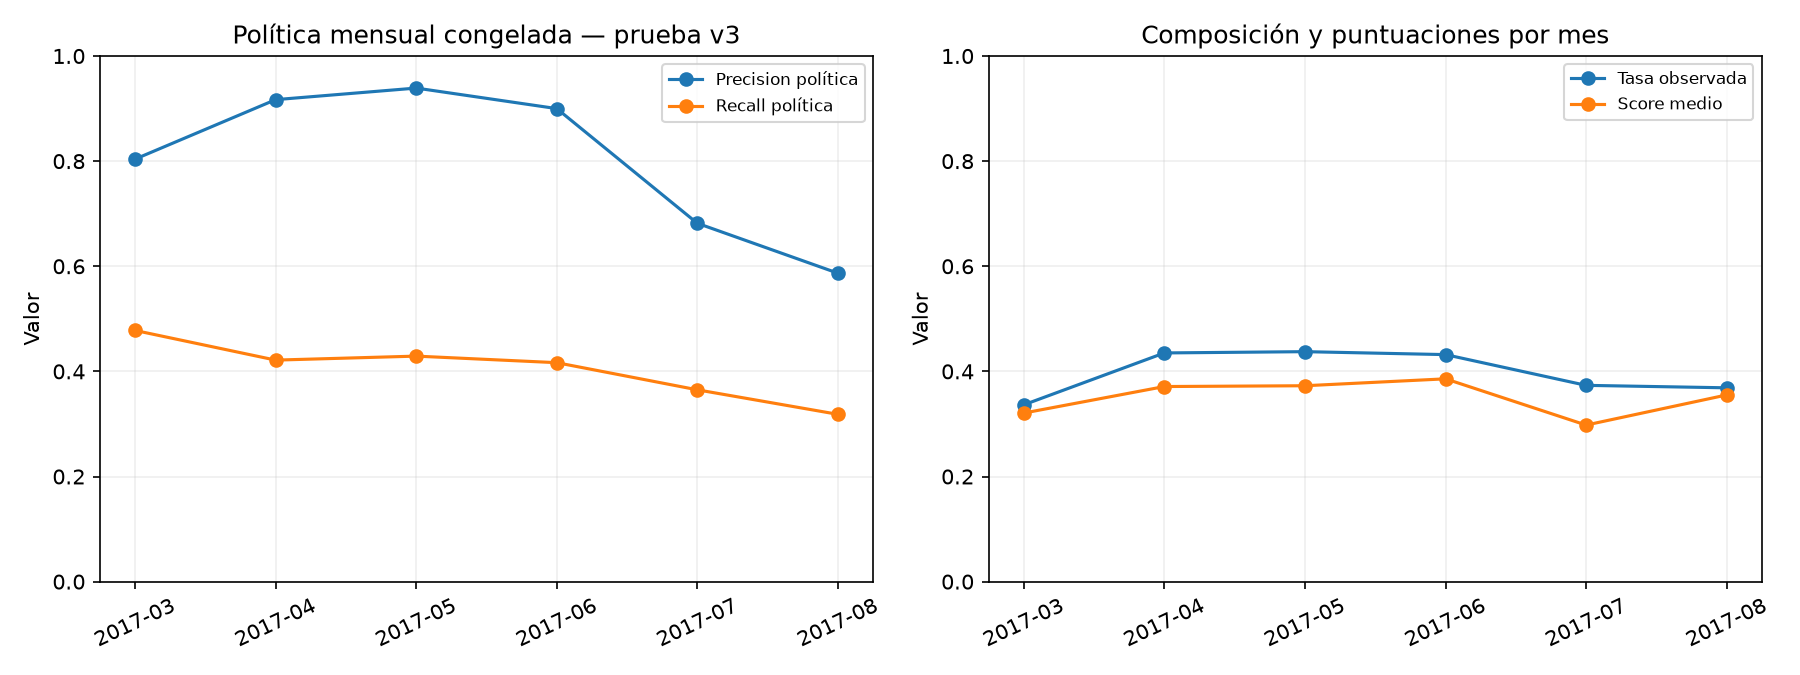

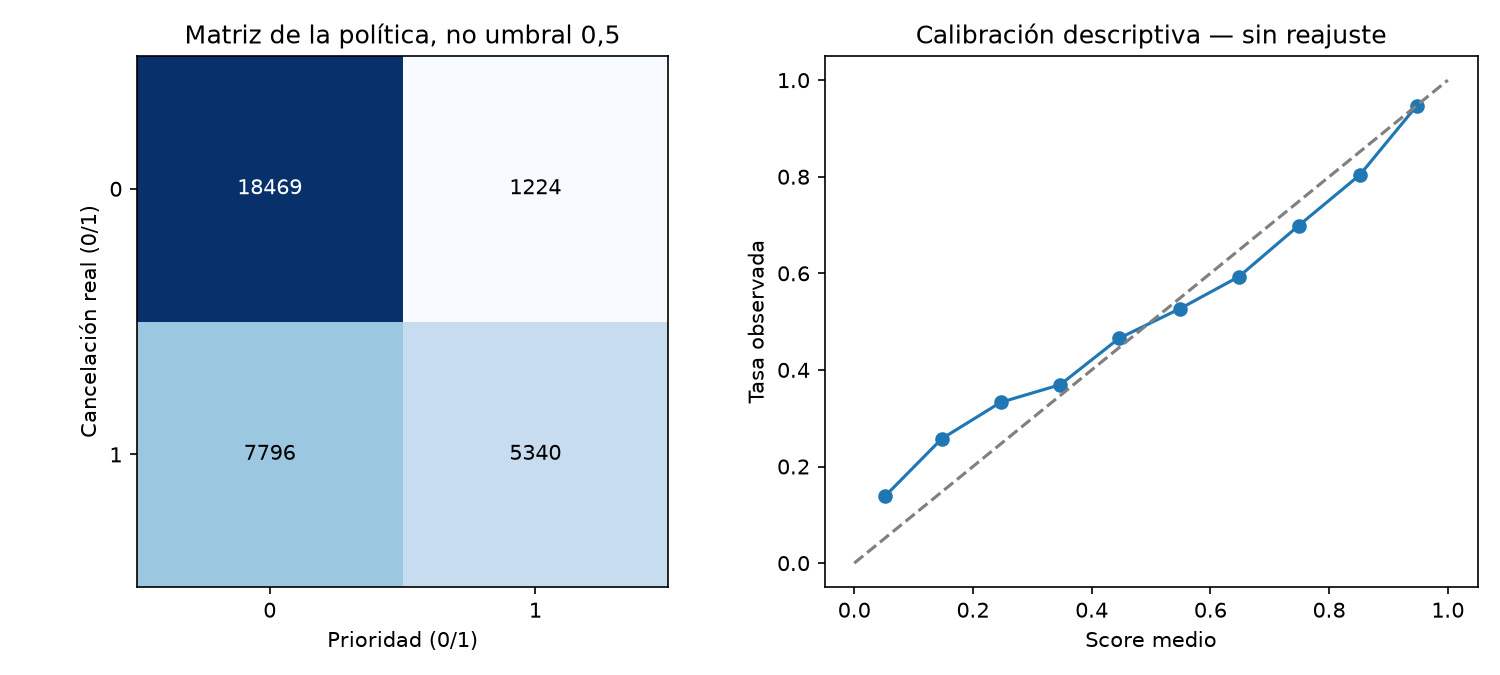

In [3]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Comprobar cupos exactos por mes y describir diferencias por hotel y composición.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
display(tables["mensual"][["mes_llegada","n","canceladas","priorizadas","tp","fp","precision","recall"]].round(6))
# Hacer explícito este invariante: si falla, no se deben interpretar los resultados como válidos.
assert (tables["mensual"].priorizadas==tables["mensual"].n*20//100).all()
display(tables["hoteles"].round(6))
display(tables["composicion"].round(6))
for name in ["mensual","matriz_calibracion"]:
 display(Image(filename=str(ROOT/f"reports/figures/evaluacion_9_{name}.png")))

## 4. Incertidumbre descriptiva

500 réplicas, seed42, bloques móviles no circulares de 14 días; cada día se arrastra completo con ambos hoteles, sin asumir independencia de filas. Se preservan scores/alertas: no se recalcula cuota ni se predice en réplicas. Los intervalos percentiles son condicionales a decisiones ya congeladas; no describen entrenamiento/selección o aplicar una cuota en una cohorte nueva. Dependencia de mayor alcance, estacionalidad y seis meses limitan estacionariedad y cobertura. No son garantías de producción. El plan se fijó antes de observar etiquetas.

In [4]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Mostrar incertidumbre por bloques y seguimiento proxy sin retirar filas.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
display(tables["intervalos"].round(6))
print("Seguimiento proxy (sin retirar filas):",result["seguimiento_proxy"])

,metrica,estimacion,p2_5,p97_5,replicas_validas
0,precision,0.813528,0.754685,0.887610,500
1,recall,0.406516,0.372366,0.436153,500
2,f1,0.542132,0.501230,0.581212,500
3,roc_auc,0.780186,0.747773,0.810234,500
4,average_precision,0.741601,0.693102,0.797401,500
5,brier,0.185340,0.171857,0.200392,500
6,tasa_cancelacion,0.400134,0.381513,0.424930,500
7,probabilidad_media,0.352073,0.335346,0.371569,500


Seguimiento proxy (sin retirar filas): {'cierre_asumido_exclusivo': '2018-12-01', 'cierre_operativo_acreditado': None, 'max_disponibilidad_proxy': '2017-09-15', 'estados_proxy_no_anteriores_cierre': 0, 'filas_retiradas': 0, 'no_garantiza_integridad_real': True}


## 5. Limitaciones y reproducción

V3 retrospectivo por llegada no simula el alta. Faltan snapshots iniciales, fecha real de creación/primera disponibilidad, cierre PMS y seguimiento acreditados. Parte de prueba se vio en desarrollo v2 y el EDA, y la política/modelo se eligieron con validación. Se conservan duplicados, no hay costes o eficacia de intervención reales, y se requiere lote mensual completo para priorizar. No se atribuye causalidad ni se autoriza despliegue o penalizaciones.

La reejecución verifica checkpoints y vuelve a presentar los mismos resultados sin nueva inferencia. No se ejecuta la batería histórica que entrena algoritmos: las pruebas de esta fase y de política son puras o con dobles de inferencia, sin ajustar modelos. Consultar fase_9_evaluacion_final.md para conclusiones y evidencia. No se avanza a fase 10.

## Lectura final de la evidencia congelada

Se priorizan 6564 reservas de 32829: 5340 TP, 1224 FP, 7796 FN y 18469 TN. Precision 81,35%, recall 40,65%, F1 0,54213; ROC-AUC 0,78019 y AP 0,74160. Brier 0,18534, tasa observada 40,01% y score medio 35,21%.

Respecto a validación, precision baja 4,25 puntos y recall 4,35, con mayor prevalencia. El deterioro descriptivo se concentra al final del periodo: precision de mayo 93,90%, julio 68,17% y agosto 58,68%; no se atribuye a una causa única o tendencia uniforme. Cambian mercado/tipo de cliente y antelación, mientras la proporción de hoteles es parecida. City recibe 23,73% de alertas sobre sus filas y Resort 11,81%, conforme a una cuota compartida, sin redistribución.

Las réplicas por bloques dan intervalos ilustrativos condicionados a decisiones originales, no garantías prospectivas o significación frente a validación. No se cambia ninguna decisión por estos resultados. La inferencia y sus decisiones ya están congeladas; esta ejecución de presentación reutiliza el recibo sin volver a predecir. El informe amplía las limitaciones.

In [5]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Comprobar política y evaluación con pruebas que no entrenan modelos.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
import io,unittest
from src.comparison import sha
suite=unittest.TestSuite()
for pattern in ["test_final_evaluation.py","test_decision_policy.py"]:
 # Seleccionar las pruebas de esta llamada; los conjuntos históricos pueden incluir entrenamientos.
 suite.addTests(unittest.defaultTestLoader.discover(str(ROOT/"tests"),pattern=pattern))
log=io.StringIO();test_result=unittest.TextTestRunner(stream=log).run(suite)
print(log.getvalue());assert test_result.wasSuccessful()
check=json.loads((ROOT/"reports/evaluacion_9_preflight.json").read_text(encoding="utf-8"))
for path,expected in check["archivos_previos_sha256"].items(): assert sha(ROOT/path)==expected,path
# Hacer explícito este invariante: si falla, no se deben interpretar los resultados como válidos.
assert receipt["llamadas_predict_proba"]==1
# Hacer explícito este invariante: si falla, no se deben interpretar los resultados como válidos.
assert receipt["reentrenamientos"]==receipt["recalibraciones"]==0
# Hacer explícito este invariante: si falla, no se deben interpretar los resultados como válidos.
assert receipt["etiquetas_leidas_despues_de_congelacion_scores"]
print("Pruebas sin entrenamiento superadas:",test_result.testsRun)
print("Fin exclusivo de fase 9.")

............
----------------------------------------------------------------------
Ran 12 tests in 0.383s

OK

Pruebas sin entrenamiento superadas: 12
Fin exclusivo de fase 9.
